In [47]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

In [48]:
movies = pd.read_csv('movies.csv')
ratings = pd.read_csv('ratings.csv')
data = movies.merge(ratings, on='movieId')

In [49]:
data.head(50)

,movieId,title,genres,userId,rating,timestamp
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1,4.0,964982703
1,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,5,4.0,847434962
2,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,7,4.5,1106635946
3,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,15,2.5,1510577970
4,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,17,4.5,1305696483
5,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,18,3.5,1455209816
6,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,19,4.0,965705637
7,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,21,3.5,1407618878
8,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,27,3.0,962685262
9,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,31,5.0,850466616


In [50]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 6 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   movieId    100836 non-null  int64  
 1   title      100836 non-null  str    
 2   genres     100836 non-null  str    
 3   userId     100836 non-null  int64  
 4   rating     100836 non-null  float64
 5   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 8.9 MB


In [51]:
data.duplicated().sum()

np.int64(0)

In [52]:
print("Missing values in ratings:")
print(ratings.isnull().sum())
print("\nMissing values in movies:")
print(movies.isnull().sum())

print("\nDuplicate user-movie pairs:", ratings.duplicated(["userId", "movieId"]).sum())
print("Movies with no genre listed:", (movies["genres"] == "(no genres listed)").sum())
print("Distinct rating values:", sorted(ratings["rating"].unique()))

Missing values in ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Missing values in movies:
movieId    0
title      0
genres     0
dtype: int64

Duplicate user-movie pairs: 0
Movies with no genre listed: 34
Distinct rating values: [np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0)]


In [53]:
import pandas as pd
import re


# 1. Remove leading/trailing spaces
data["title"] = data["title"].astype(str).str.strip()

# 2. Replace multiple spaces with a single space
data["title"] = data["title"].str.replace(r"\s+", " ", regex=True)


# 8. Save cleaned file
data.to_csv("movies_cleaned.csv", index=False)


data.duplicated().sum()


np.int64(0)

In [54]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 6 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   movieId    100836 non-null  int64  
 1   title      100836 non-null  str    
 2   genres     100836 non-null  str    
 3   userId     100836 non-null  int64  
 4   rating     100836 non-null  float64
 5   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 8.9 MB


In [55]:
data.head(50)

,movieId,title,genres,userId,rating,timestamp
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1,4.0,964982703
1,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,5,4.0,847434962
2,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,7,4.5,1106635946
3,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,15,2.5,1510577970
4,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,17,4.5,1305696483
5,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,18,3.5,1455209816
6,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,19,4.0,965705637
7,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,21,3.5,1407618878
8,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,27,3.0,962685262
9,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,31,5.0,850466616


In [56]:
print("Missing values in ratings:")
print(ratings.isnull().sum())
print("\nMissing values in movies:")
print(movies.isnull().sum())

print("\nDuplicate user-movie pairs:", ratings.duplicated(["userId", "movieId"]).sum())
print("Movies with no genre listed:", (movies["genres"] == "(no genres listed)").sum())
print("Distinct rating values:", sorted(ratings["rating"].unique()))

# Do all rated movies exist in movies.csv?
print("Rated movieIds missing from movies.csv:",
      (~ratings["movieId"].isin(movies["movieId"])).sum())

Missing values in ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Missing values in movies:
movieId    0
title      0
genres     0
dtype: int64

Duplicate user-movie pairs: 0
Movies with no genre listed: 34
Distinct rating values: [np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0)]
Rated movieIds missing from movies.csv: 0


In [58]:
data = data[data['genres'] != '(no genres listed)']

data.info()

<class 'pandas.DataFrame'>
Index: 100789 entries, 0 to 100835
Data columns (total 6 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   movieId    100789 non-null  int64  
 1   title      100789 non-null  str    
 2   genres     100789 non-null  str    
 3   userId     100789 non-null  int64  
 4   rating     100789 non-null  float64
 5   timestamp  100789 non-null  int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 9.7 MB


Dropped rows with not genres (no genres listed)

In [59]:
data.describe()

,movieId,userId,rating,timestamp
count,100789.000000,100789.000000,100789.000000,1.007890e+05
mean,19373.299299,326.123307,3.501563,1.205803e+09
std,35420.417225,182.603725,1.042448,2.162089e+08
min,1.000000,1.000000,0.500000,8.281246e+08
25%,1199.000000,177.000000,3.000000,1.018184e+09
50%,2990.000000,325.000000,3.500000,1.186086e+09
75%,8014.000000,477.000000,4.000000,1.435994e+09
max,193609.000000,610.000000,5.000000,1.537799e+09


Text(0.5, 0, 'Rating')

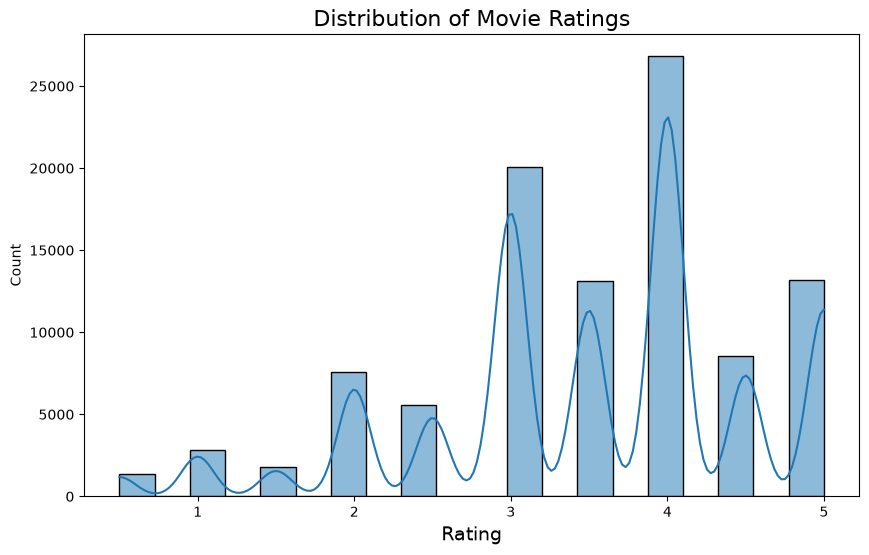

In [63]:
plt.figure(figsize=(10, 6))
sns.histplot(data['rating'], bins=20, kde=True) 
plt.title('Distribution of Movie Ratings', fontsize=16)
plt.xlabel('Rating', fontsize=14)

Text(0, 0.5, 'Count')

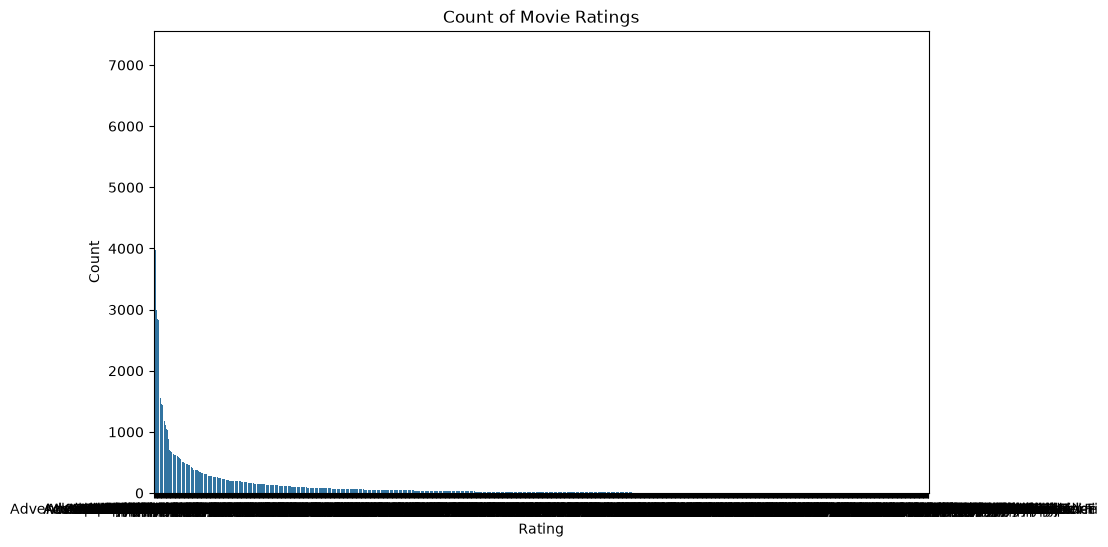

In [69]:
plt.figure(figsize=(10, 6))
genre_counts = data['genres'].value_counts()
sns.barplot(x=genre_counts.index, y=genre_counts.values)
plt.title('Count of Movie Ratings')
plt.xlabel('Rating')
plt.ylabel('Count')